# PySpark K-Medoids: the second Spark algorithm

We execute the same Manhattan PAM SWAP procedure as Phase 7 with k=2, frozen standardized profiles, identical saved initial medoids, tolerance and stopping limit. Workers compute/cache distance rows and aggregate every candidate-swap cost. The driver combines partial costs and selects the globally best improving swap. No K-Means model is used.

This independent notebook avoids rerunning Phase 9 FP-Growth benchmarks. We measure three warmed repetitions per engine after one excluded warm-up. Both engines use prepared pairwise distances, so timings compare SWAP iterations and materialized assignments; BUILD and distance preparation are recorded/excluded consistently.

In [1]:
from pathlib import Path
import sys, os, warnings
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/prison-mpl")
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from src.mining.spark_k_medoids import run_spark_k_medoids
sns.set_theme(style="whitegrid")

## Execute the distributed algorithm and comparison

The source reads the saved Spark feature schema, checks exact input-vector equality, broadcasts the small feature matrix, caches separately computed distance rows on workers, and distributes cost/assignment evaluation using `mapPartitions`. Input/cache creation, startup and the first fit are recorded separately. The process/JVM RSS method follows Phase 9 and also includes Spark Python workers.

The specific pandas integration warning is filtered within this JSON/RDD workflow; pandas conversion, pandas UDFs and Arrow are not used.

In [2]:
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=r"PySpark does not yet fully support pandas >= 3\.0\.0\..*", category=FutureWarning)
    summary = run_spark_k_medoids(ROOT, repetitions=3)
TABLES = ROOT / "results/tables/spark_k_medoids"
BENCHMARKS = ROOT / "results/benchmarks/spark_k_medoids"
PLOTS = ROOT / "results/plots/spark_k_medoids"
PLOTS.mkdir(parents=True, exist_ok=True)
equivalence = pd.read_csv(TABLES / "equivalence.csv")
timings = pd.read_csv(BENCHMARKS / "timing_runs.csv")
comparison = pd.read_csv(BENCHMARKS / "timing_summary.csv")
display(equivalence)
display(pd.read_csv(TABLES / "medoids.csv"))
display(comparison)
print("Objective:", summary["objective"], "Silhouette:", summary["silhouette"])
print("Observed cold session/preparation/first-fit sum:", summary["cold_spark_observed_seconds"])

,initialization,ari,objective_difference,max_assignment_distance_difference,max_candidate_swap_cost_difference,equivalent
0,phase7_selected_initial,1.0,6.821210e-13,0.0,1.364242e-12,True
1,random_seed_42,1.0,1.364242e-12,0.0,2.273737e-12,True


,profile_id,state,year,occupancy_ratio,undertrial_share,female_share,age_18_30_share,illiterate_share,cluster
0,Jharkhand|2007,Jharkhand,2007,1.670330,0.672558,0.036630,0.465656,0.362511,0
1,Kerala|2002,Kerala,2002,0.885475,0.666538,0.036045,0.432537,0.232074,1


,python_median_seconds,spark_median_seconds,python_min_seconds,python_max_seconds,spark_min_seconds,spark_max_seconds,speedup_python_over_spark,spark_over_python_ratio
0,0.006449,0.194666,0.004758,0.006879,0.184895,0.197901,0.033129,30.185355


Objective: 1459.8623650936208 Silhouette: 0.17447707939550836
Observed cold session/preparation/first-fit sum: 5.78984000699711


## Compare actual materialized runtimes

Speedup = Python median / Spark median. Below one means Spark is slower. Error bars show the observed minimum–maximum range of three runs, not confidence intervals. Memory observations represent scoped resident process footprints rather than isolated allocations.

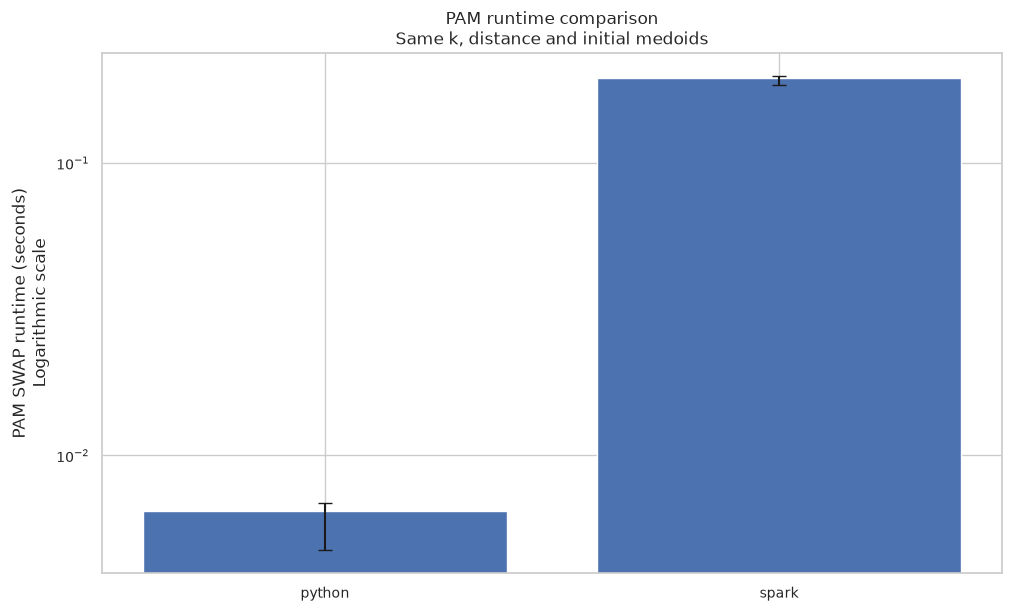

Speedup (Python / Spark): 0.033128648105998026
Spark / Python runtime ratio: 30.18535488681615


,engine,repetition,warmup,seconds,rss_baseline_mib,sampled_peak_rss_mib,objective,swaps
0,python,0,True,0.007422,245.414062,245.421875,1459.862365,1
1,spark,0,True,0.203096,1163.746094,1184.500000,1459.862365,1
2,python,1,False,0.004758,245.746094,245.746094,1459.862365,1
3,spark,1,False,0.194666,1184.570312,1199.332031,1459.862365,1
4,spark,2,False,0.197901,1199.371094,1210.046875,1459.862365,1
5,python,2,False,0.006879,245.835938,245.835938,1459.862365,1
6,python,3,False,0.006449,245.835938,245.835938,1459.862365,1
7,spark,3,False,0.184895,1210.046875,1212.417969,1459.862365,1


In [3]:
row = comparison.iloc[0]
engines = ["python", "spark"]
medians = np.array([row[f"{engine}_median_seconds"] for engine in engines])
lower = medians - np.array([row[f"{engine}_min_seconds"] for engine in engines])
upper = np.array([row[f"{engine}_max_seconds"] for engine in engines]) - medians
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
ax.bar(engines, medians, yerr=np.vstack([lower, upper]), capsize=5)
ax.set_yscale("log")
ax.set_ylabel("PAM SWAP runtime (seconds)\nLogarithmic scale")
ax.set_title("PAM runtime comparison\nSame k, distance and initial medoids")
ax.tick_params(axis="both", labelsize=10)
fig.savefig(PLOTS / "runtime_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Speedup (Python / Spark):", row.speedup_python_over_spark)
print("Spark / Python runtime ratio:", row.spark_over_python_ratio)
display(timings)

## Verify the optimization trajectory

Both real initializations are compared with Python. We verify medoid IDs, all assignments/distances, objective, every accepted swap and the full candidate-swap cost table at each visited medoid set. The ARI compares partitions up to cluster-label permutation, not classification accuracy.

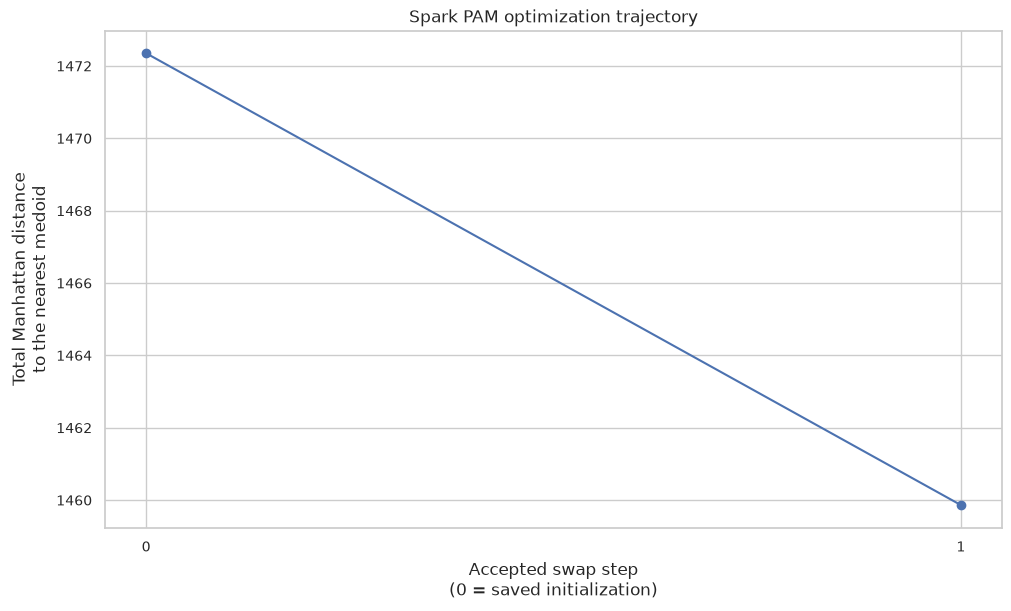

,step,cost,removed,added,medoid_indices
0,0,1472.351595,NaN,NaN,"[193, 360]"
1,1,1459.862365,360.0,213.0,"[193, 213]"


In [4]:
trace = pd.read_csv(TABLES / "objective_trace.csv")
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
ax.plot(trace.step, trace.cost, marker="o")
ax.set_xticks(trace.step)
ax.set_xlabel("Accepted swap step\n(0 = saved initialization)")
ax.set_ylabel("Total Manhattan distance\nto the nearest medoid")
ax.set_title("Spark PAM optimization trajectory")
ax.tick_params(axis="both", labelsize=10)
fig.savefig(PLOTS / "objective_trace.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
display(trace)

## Limits and final checks

A complete feature matrix is broadcast for this small experiment, cached pairwise distances use O(n²) space, and the driver retains an O(k n) aggregate cost table. This is genuine distributed cost evaluation on one host; it is not a claim of large-data scalability. Initialization is supplied identically on both sides, so BUILD initialization/model selection is not benchmarked again.

The weak cluster separation and initialization sensitivity found in Phase 7 remain. Agreement between implementations does not make those clusters stronger or causal. No performance enhancement is assumed. The report records the measured result. Phase 11 requires separate approval.

In [5]:
from src.preprocessing.cleaning import sha256
assert equivalence.equivalent.all()
assert np.allclose(equivalence.ari, 1)
assert summary["input_roundtrip_equivalent"]
for item in summary["inputs"]:
    assert sha256(ROOT / item["file"]) == item["sha256"]
print("Verified equivalent vectors, medoids, partitions, trajectories and unchanged inputs.")

Verified equivalent vectors, medoids, partitions, trajectories and unchanged inputs.


References: [Spark RDD programming](https://spark.apache.org/docs/latest/rdd-programming-guide.html), [Phase 7 methodology](../report/k_medoids.md), [Phase 10 report](../report/spark_k_medoids.md).